<a href="https://colab.research.google.com/github/bchgacor/Data-Transaksi-Restoran---Data-Visualization/blob/main/DataVisualization2418029.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROJEK DATA MINING - DATA Visualization RESTORAN

# Inisialisasi Tampilan, Pembersihan Anomali, dan Standarisasi Data Transaksi Restoran

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from google.colab import files

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Memuat file data yang sudah bersih dari Colab cleansing
df = pd.read_excel('Cleaned_Data_Restoran.xlsx')

# Pengaman: buang anomali nilai transaksi ekstrem (puluhan juta, dst.)
# Menu termahal normal ~Rp105.000/transaksi, jadi batas Rp200.000 sudah longgar.
BATAS_ANOMALI = 200_000
n_awal = len(df)
df = df[~(df["Total_Bayar"] > BATAS_ANOMALI)].copy()
print(f"Baris dibuang karena anomali: {n_awal - len(df)}")

# Persiapan kolom waktu
df["Waktu_Pesanan"] = pd.to_datetime(df["Waktu_Pesanan"])
df["Bulan"] = df["Waktu_Pesanan"].dt.to_period("M")
df["Tanggal"] = df["Waktu_Pesanan"].dt.date

# Samakan penulisan metode pembayaran
df["Metode_Pembayaran"] = df["Metode_Pembayaran"].replace({"Credit": "Credit Card"})

# Pengaturan tampilan
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})
rupiah = mtick.FuncFormatter(lambda x, _: f"Rp{x:,.0f}".replace(",", "."))

print(f"Data siap: {len(df)} baris, periode {df['Waktu_Pesanan'].min():%d %b %Y} - {df['Waktu_Pesanan'].max():%d %b %Y}")
df.head()

Baris dibuang karena anomali: 6
Data siap: 144 baris, periode 01 Sep 2026 - 14 Sep 2026


,ID_Pesanan,Menu,Jumlah,Harga,Pelanggan,Waktu_Pesanan,Metode_Pembayaran,Total_Bayar,Kategori_Pesanan,Bulan,Tanggal
0,ORD-001,Nasi Goreng Spesial,2,25000.0,Raditya,2026-09-01 12:30:00,Cash,50000.0,Besar,2026-09,2026-09-01
1,ORD-002,Ayam Bakar,1,30000.0,Margaretha,2026-09-01 12:35:00,Transfer,30000.0,Reguler,2026-09,2026-09-01
2,ORD-003,Es Teh Manis,1,5000.0,Billy,2026-09-01 12:40:00,Cash,5000.0,Reguler,2026-09,2026-09-01
3,ORD-004,Mie Goreng,2,22000.0,Raditya,2026-09-01 12:45:00,QRIS,44000.0,Reguler,2026-09,2026-09-01
4,ORD-005,Es Jeruk,1,7000.0,Gilang,2026-09-01 13:00:00,QRIS,7000.0,Reguler,2026-09,2026-09-01


# Data Visualization - Line Chart Tren Pertumbuhan GMV per Bulan

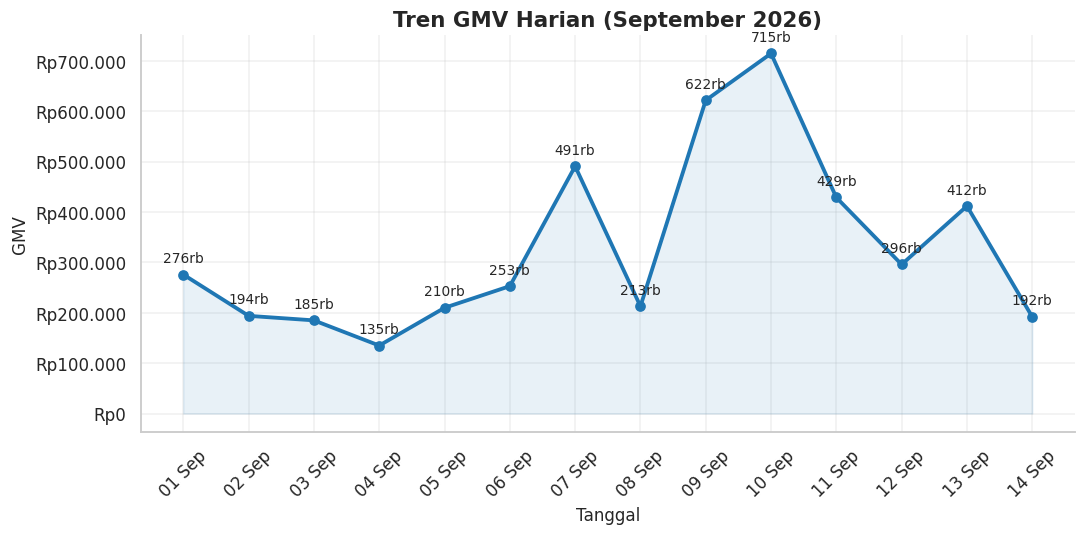

In [107]:
# GMV = total nilai transaksi (Total_Bayar)
gmv_bulan = df.groupby("Bulan")["Total_Bayar"].sum()

if len(gmv_bulan) >= 2:
    x = gmv_bulan.index.strftime("%b %Y"); y = gmv_bulan.values
    judul, xlabel = "Tren Pertumbuhan GMV per Bulan", "Bulan"
else:
    # Data hanya mencakup 1 bulan -> tampilkan tren harian agar tetap informatif
    harian = df.groupby("Tanggal")["Total_Bayar"].sum()
    x = [pd.Timestamp(t).strftime("%d %b") for t in harian.index]; y = harian.values
    judul = f"Tren GMV Harian ({gmv_bulan.index[0].strftime('%B %Y')})"
    xlabel = "Tanggal"

fig, ax = plt.subplots()
ax.plot(x, y, marker="o", linewidth=2.5, color="#1f77b4")
ax.fill_between(range(len(y)), y, alpha=0.1, color="#1f77b4")
for i, v in enumerate(y):
    ax.annotate(f"{v/1000:,.0f}rb", (i, v), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)
ax.yaxis.set_major_formatter(rupiah)
ax.set_title(judul, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel("GMV")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Data Visualization - Bar Chart Jumlah Order per Bulan

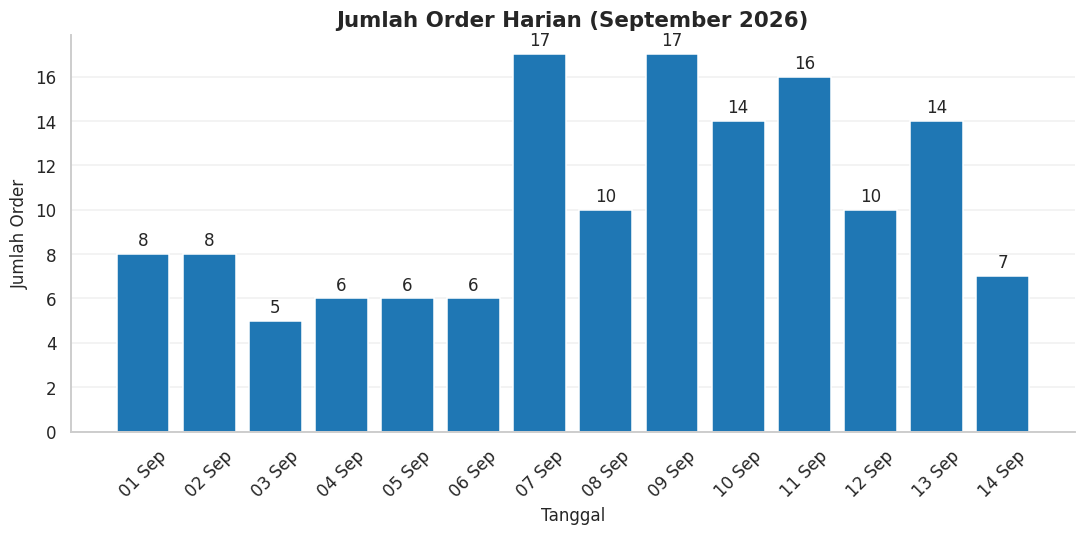

In [108]:
order_bulan = df.groupby("Bulan")["ID_Pesanan"].nunique()

if len(order_bulan) >= 2:
    x = order_bulan.index.strftime("%b %Y"); y = order_bulan.values
    judul, xlabel = "Jumlah Order per Bulan", "Bulan"
else:
    harian = df.groupby("Tanggal")["ID_Pesanan"].nunique()
    x = [pd.Timestamp(t).strftime("%d %b") for t in harian.index]; y = harian.values
    judul = f"Jumlah Order Harian ({order_bulan.index[0].strftime('%B %Y')})"
    xlabel = "Tanggal"

fig, ax = plt.subplots()
bars = ax.bar(x, y, color="#1f77b4")
ax.bar_label(bars, padding=3)
ax.set_title(judul, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel("Jumlah Order")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Data Visualization - Horizontal Bar Chart Top Menu Terlaris

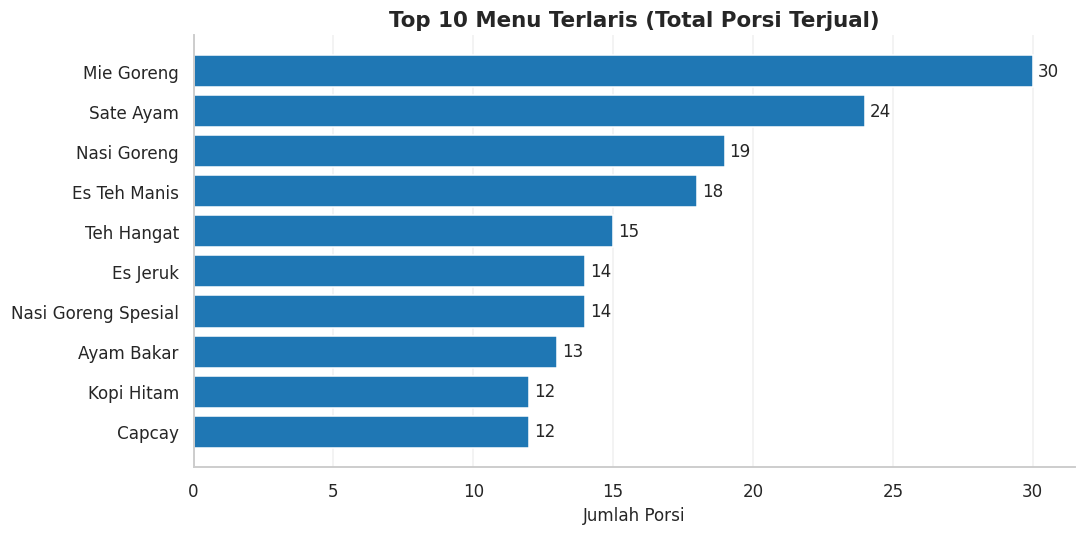

In [101]:
# Menu "Tidak Diketahui" tidak diikutkan; ukuran terlaris = total porsi terjual
top_menu = (df[df["Menu"] != "Tidak Diketahui"]
            .groupby("Menu")["Jumlah"].sum()
            .sort_values(ascending=False).head(10)
            .sort_values())          # urut naik agar yang terbesar tampil di atas

fig, ax = plt.subplots()
bars = ax.barh(top_menu.index, top_menu.values, color="#1f77b4")
ax.bar_label(bars, padding=3)
ax.set_title("Top 10 Menu Terlaris (Total Porsi Terjual)", fontweight="bold")
ax.set_xlabel("Jumlah Porsi"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

# Data Visualization - Bar Chart Distribusi Kategori Pesanan (Reguler vs Besar)

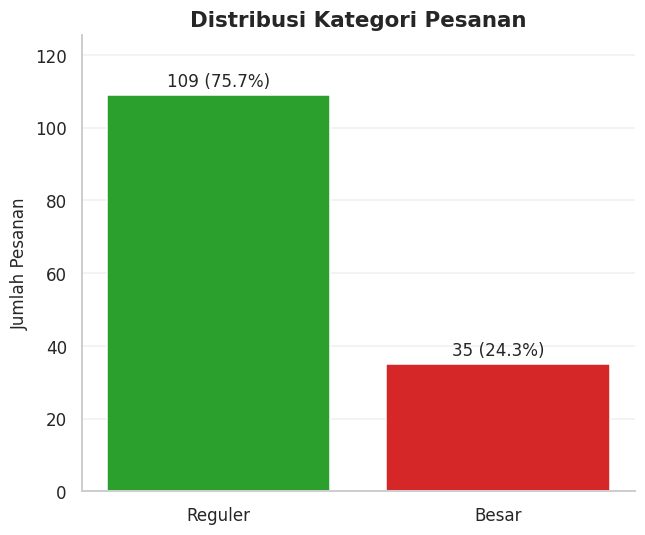

In [102]:
kategori = df["Kategori_Pesanan"].value_counts()
persen = kategori / kategori.sum() * 100

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(kategori.index, kategori.values, color=["#2ca02c", "#d62728"][:len(kategori)])
ax.bar_label(bars, labels=[f"{v} ({p:.1f}%)" for v, p in zip(kategori.values, persen)], padding=3)
ax.set_title("Distribusi Kategori Pesanan", fontweight="bold")
ax.set_ylabel("Jumlah Pesanan"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, kategori.max() * 1.15)
plt.tight_layout(); plt.show()

# Data Visualization - Histogram Sebaran Nilai GMV per Transaksi

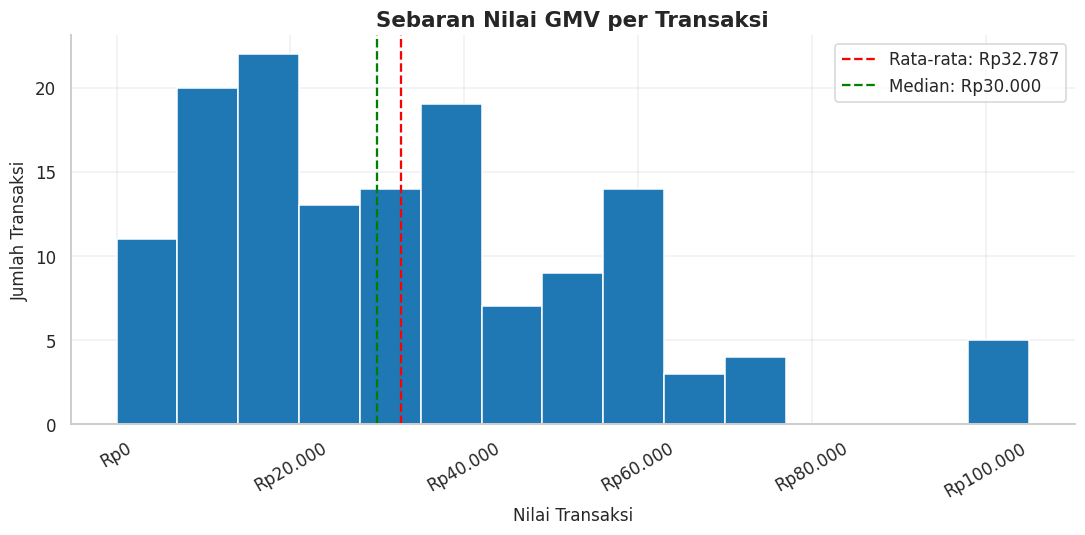

In [103]:
nilai = df["Total_Bayar"].dropna()

fig, ax = plt.subplots()
ax.hist(nilai, bins=15, color="#1f77b4", edgecolor="white")
ax.axvline(nilai.mean(), color="red", linestyle="--", label=f"Rata-rata: Rp{nilai.mean():,.0f}".replace(",", "."))
ax.axvline(nilai.median(), color="green", linestyle="--", label=f"Median: Rp{nilai.median():,.0f}".replace(",", "."))
ax.xaxis.set_major_formatter(rupiah)
ax.set_title("Sebaran Nilai GMV per Transaksi", fontweight="bold")
ax.set_xlabel("Nilai Transaksi"); ax.set_ylabel("Jumlah Transaksi")
ax.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# Data Visualization - Ringkasan Hasil Analisis Otomatis

In [105]:
total_order = len(df)
total_gmv = df['Total_Bayar'].sum()
rata_rata_gmv = df['Total_Bayar'].mean()
top_item = df['Menu'].mode()[0] if 'Menu' in df.columns else "Tidak Ada"

print("=" * 55)
print("     RINGKASAN VISUALISASI DATA TRANSAKSI RESTORAN     ")
print("=" * 55)
print(f"Total Pesanan Transaksi        : {total_order}")
print(f"Total Nominal Nilai Transaksi  : Rp{total_gmv:,.0f}".replace(",", "."))
print(f"Rata-rata Nilai per Pesanan    : Rp{rata_rata_gmv:,.0f}".replace(",", "."))
print(f"Menu Paling Sering Dipesan     : {top_item}")
print("=" * 55)

     RINGKASAN VISUALISASI DATA TRANSAKSI RESTORAN     
Total Pesanan Transaksi        : 144
Total Nominal Nilai Transaksi  : Rp4.623.000
Rata-rata Nilai per Pesanan    : Rp32.787
Menu Paling Sering Dipesan     : Mie Goreng
